Cell 0 — Imports

In [17]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import json
from datetime import datetime


Cell 1 ** — Step 1 helpers (global state) - OU process for mean-Reverting

In [18]:
def simulate_global_state_ou(
        T=20000, D=256, seed=123, 
        mu=-1.5, sigma=0.3, 
        sigma_drift=0.001,
        lambda_ou = 0.03,        # mean-reversion strength (0 -> random walk) - A good starting value is 0.02 to 0.05.
        eps0 = 0.0               # long-run mean of eps
):
    """
    Ou drift:
    eps_t = (1 - lambda_ou) * eps_{t-1} + lambda_ou * eps0 + Normal(0, sigma_drift)
    then eps enters the logistic transition probabilities.
    """
    rng = np.random.default_rng(seed)

    alpha = rng.normal(mu, sigma, size=D)
    beta  = rng.normal(mu, sigma, size=D)

    eps = np.zeros(D) + eps0
    X = np.zeros((T, D), dtype=np.int8)
    X[0] = rng.binomial(1, 0.5, size=D)

    for t in range(1, T):
        # OU update (mean-reverting)
        eps += (1.0 - lambda_ou) * eps + lambda_ou * eps0 + rng.normal(0.0, sigma_drift, size=D)

        p = 1 / (1 + np.exp(-(alpha + eps)))
        q = 1 / (1 + np.exp(-(beta  + eps)))

        X[t] = rng.binomial(1, np.where(X[t-1]==0, p, 1-q))

    return X


Cell 2 — Step 2 helpers (nodes + signals)

In [19]:
def construct_nodes(D=256, K=40, subset_size=25, overlap_target=5, seed=123):
    rng = np.random.default_rng(seed)
    subsets = [set(rng.choice(D, subset_size, replace=False))]
    for _ in range(1, K):
        base_subset = subsets[rng.integers(len(subsets))]
        base = rng.choice(list(base_subset), overlap_target, replace=False)
        rest = rng.choice(list(set(range(D)) - set(base)), subset_size - overlap_target, replace=False)
        subsets.append(set(base) | set(rest))
    return subsets

def compute_node_signals(X, subsets):
    Z = np.zeros((X.shape[0], len(subsets)), dtype=np.float32)
    for k, S in enumerate(subsets):
        Z[:, k] = X[:, list(S)].mean(axis=1)
    return Z


Cell 3 — Step 5 destruction helper (bit-flip)

In [20]:
def destroy_bitflip_X(X, delta, seed=999):
    rng = np.random.default_rng(seed)
    flips = rng.random(X.shape) < delta
    Xd = X.copy()
    Xd[flips] = 1 - Xd[flips]
    return Xd


Cell 4 — Step 4 dataset used for evaluation (masked windows)

In [21]:
class MaskedWindowDataset(Dataset):
    def __init__(self, Z, window=128, mask_ratio=0.15, seed=2):
        rng = np.random.default_rng(seed)
        T, K = Z.shape
        self.Z = Z.astype(np.float32)
        self.window = window
        self.N = T - window
        self.masks = rng.random((self.N, window, K)) < mask_ratio

    def __len__(self):
        return self.N

    def __getitem__(self, idx):
        x = self.Z[idx:idx+self.window].copy()
        m = self.masks[idx]
        y = x.copy()
        x[m] = 0.0
        return torch.from_numpy(x), torch.from_numpy(m), torch.from_numpy(y)


Cell 5 — Model class (must match training)

In [22]:
class MaskedTimeTransformer(nn.Module):
    def __init__(self, K, window=128, d_model=128, nhead=4, num_layers=3, dim_ff=256, dropout=0.1):
        super().__init__()
        self.in_proj = nn.Linear(K, d_model)
        self.pos_emb = nn.Parameter(torch.randn(window, d_model) * 0.02)

        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_ff,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.out_proj = nn.Linear(d_model, K)

    def forward(self, x):
        B, L, _ = x.shape
        h = self.in_proj(x) + self.pos_emb[:L].unsqueeze(0)
        h = self.encoder(h)
        return self.out_proj(h)


Cell 6 — Load model weights

In [23]:
device = "cuda" if torch.cuda.is_available() else "cpu"

K = 40
window = 128
mask_ratio = 0.15

model = MaskedTimeTransformer(K=K, window=window).to(device)
model.load_state_dict(torch.load("run1_clean_model.pt", map_location=device))
model.eval()

print("loaded on", device)


loaded on cpu


C:\Users\user\AppData\Local\Temp\ipykernel_9748\2184215657.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("run1_clean_model.pt", map_lo

Cell 7 — Step 7 info-theory utilities + collectors + baseline

In [24]:
def discretize(x, bins):
    return np.digitize(x, bins) - 1

def entropy_from_counts(counts):
    p = counts / counts.sum()
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))

def mutual_information(x, y):
    xy = np.stack([x, y], axis=1)
    _, cxy = np.unique(xy, axis=0, return_counts=True)
    _, cx = np.unique(x, return_counts=True)
    _, cy = np.unique(y, return_counts=True)
    Hx = entropy_from_counts(cx)
    Hy = entropy_from_counts(cy)
    Hxy = entropy_from_counts(cxy)
    return Hx + Hy - Hxy

def H_from_samples(x):
    _, cx = np.unique(x, return_counts=True)
    return entropy_from_counts(cx)

@torch.no_grad()
def collect_masked_predictions(model, loader, device):
    model.eval()
    z_true, z_pred = [], []
    for xb, mb, yb in loader:
        xb = xb.to(device).float()
        m = mb.numpy().astype(bool)
        y = yb.numpy().astype(np.float32)
        yhat = model(xb).cpu().numpy().astype(np.float32)
        z_true.append(y[m])
        z_pred.append(yhat[m])
    return np.concatenate(z_true), np.concatenate(z_pred)

def baseline_predict_window_node_mean(x_masked_np):
    node_means = x_masked_np.mean(axis=1, keepdims=True)  # (B,1,K)
    return np.repeat(node_means, x_masked_np.shape[1], axis=1)

def collect_baseline_window_predictions(val_loader):
    z_true, z_pred = [], []
    for xb, mb, yb in val_loader:
        x = xb.numpy().astype(np.float32)
        m = mb.numpy().astype(bool)
        y = yb.numpy().astype(np.float32)
        yhat = baseline_predict_window_node_mean(x)
        z_true.append(y[m])
        z_pred.append(yhat[m])
    return np.concatenate(z_true), np.concatenate(z_pred)


Cell 8 ** — Build base data once (for Step 7 sweeps)

In [25]:
T = 20000
seed_world = 123
seed_nodes = 123

X = simulate_global_state_ou(T=T, seed=seed_world)
subsets = construct_nodes(K=K, seed=seed_nodes)
Z = compute_node_signals(X, subsets)
split = int(0.8 * Z.shape[0])

bins = np.linspace(0, 1, 21)


C:\Users\user\AppData\Local\Temp\ipykernel_9748\1924112819.py:26: RuntimeWarning: overflow encountered in exp
  p = 1 / (1 + np.exp(-(alpha + eps)))
C:\Users\user\AppData\Local\Temp\ipykernel_9748\1924112819.py:27: RuntimeWarning: overflow encountered in exp
  q = 1 / (1 + np.exp(-(beta  + eps)))
C:\Users\user\AppData\Local\Temp\ipykernel_9748\1924112819.py:24: RuntimeWarning: overflow encountered in add
  eps += (1.0 - lambda_ou) * eps + lambda_ou * eps0 + rng.normal(0.0, sigma_drift, size=D)


Cell 9 ** — Step 7 OU_drift sweep (you edit deltas here)

In [28]:
from torch.utils.data import DataLoader
import numpy as np

# fixed experiment settings
T = 20000
D = 256
K = 40
window = 128
mask_ratio = 0.15
bins = np.linspace(0, 1, 21)

seed_world = 123
seed_nodes = 123
lambda_ou = 0.03 #3 try 0.02-0.05

# keep subsets fixed across all sigma_drift values
X_ref = simulate_global_state_ou(T=T, D=D, seed=seed_world, sigma_drift=0.001, lambda_ou=lambda_ou)
subsets = construct_nodes(D=D, K=K, seed=seed_nodes)

def eval_on_sigma_ou(model, sigma_drift):
    X = simulate_global_state_ou(T=T, D=D, seed=seed_world, sigma_drift=sigma_drift, lambda_ou=lambda_ou)
    Z = compute_node_signals(X, subsets)
    split = int(0.8 * Z.shape[0])

    Z_val = Z[split - window:]
    val_ds = MaskedWindowDataset(Z_val, window=window, mask_ratio=mask_ratio, seed=2)
    val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)

    # transformer
    zt_tf, zp_tf = collect_masked_predictions(model, val_loader, device)
    zt_tf_d = discretize(zt_tf, bins)
    zp_tf_d = discretize(zp_tf, bins)

    H_true = H_from_samples(zt_tf_d)
    MI_tf = mutual_information(zt_tf_d, zp_tf_d)
    R_tf = MI_tf / H_true if H_true > 1e-12 else 0.0

    # baseline
    zt_b, zp_b = collect_baseline_window_predictions(val_loader)
    zt_b_d = discretize(zt_b, bins)
    zp_b_d = discretize(zp_b, bins)

    MI_b = mutual_information(zt_b_d, zp_b_d)
    R_b = MI_b / H_true if H_true > 1e-12 else 0.0

    return {
        "sigma_drift": float(sigma_drift),
        "lambda_ou": float(lambda_ou),
        "H_true": float(H_true),
        "MI_transformer": float(MI_tf),
        "R_transformer": float(R_tf),
        "MI_baseline_window": float(MI_b),
        "R_baseline_window": float(R_b),
    }

# lag-ish grid (extend it if needed)
sigmas = [0.0, 0.0005, 0.001, 0.002, 0.004, 0.008, 0.016, 0.032]

results_ou = [eval_on_sigma_ou(model, s) for s in sigmas]
results_ou

C:\Users\user\AppData\Local\Temp\ipykernel_9748\1924112819.py:26: RuntimeWarning: overflow encountered in exp
  p = 1 / (1 + np.exp(-(alpha + eps)))
C:\Users\user\AppData\Local\Temp\ipykernel_9748\1924112819.py:27: RuntimeWarning: overflow encountered in exp
  q = 1 / (1 + np.exp(-(beta  + eps)))
C:\Users\user\AppData\Local\Temp\ipykernel_9748\1924112819.py:24: RuntimeWarning: overflow encountered in add
  eps += (1.0 - lambda_ou) * eps + lambda_ou * eps0 + rng.normal(0.0, sigma_drift, size=D)


[{'sigma_drift': 0.0,
  'lambda_ou': 0.03,
  'H_true': 2.9880107380611354,
  'MI_transformer': 0.05399586573532389,
  'R_transformer': 0.018070840592213134,
  'MI_baseline_window': 0.015426229363089128,
  'R_baseline_window': 0.0051627088104438746},
 {'sigma_drift': 0.0005,
  'lambda_ou': 0.03,
  'H_true': 2.724990152203555,
  'MI_transformer': 0.05203676866800144,
  'R_transformer': 0.019096130907453764,
  'MI_baseline_window': 0.5415856773678858,
  'R_baseline_window': 0.1987477558147996},
 {'sigma_drift': 0.001,
  'lambda_ou': 0.03,
  'H_true': 2.784638844063818,
  'MI_transformer': 0.09833919861593632,
  'R_transformer': 0.03531488430737505,
  'MI_baseline_window': 0.526687410809271,
  'R_baseline_window': 0.18914029441629104},
 {'sigma_drift': 0.002,
  'lambda_ou': 0.03,
  'H_true': 2.7171148899323843,
  'MI_transformer': 0.04691143760903982,
  'R_transformer': 0.01726516526145393,
  'MI_baseline_window': 0.40256483811674926,
  'R_baseline_window': 0.14815893122825113},
 {'sigma_d

In [31]:
# build ONE validation loader explicitly for sanity checks

sigma_test = 0.002   # pick any OU sigma you tested
lambda_ou = 0.03

X_test = simulate_global_state_ou(
    T=T,
    D=256,
    seed=seed_world,
    sigma_drift=sigma_test,
    lambda_ou=lambda_ou
)

Z_test = compute_node_signals(X_test, subsets)
split = int(0.8 * Z_test.shape[0])

Z_val_test = Z_test[split - window:]
val_ds = MaskedWindowDataset(
    Z_val_test,
    window=window,
    mask_ratio=mask_ratio,
    seed=2
)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)


C:\Users\user\AppData\Local\Temp\ipykernel_9748\1924112819.py:26: RuntimeWarning: overflow encountered in exp
  p = 1 / (1 + np.exp(-(alpha + eps)))
C:\Users\user\AppData\Local\Temp\ipykernel_9748\1924112819.py:27: RuntimeWarning: overflow encountered in exp
  q = 1 / (1 + np.exp(-(beta  + eps)))
C:\Users\user\AppData\Local\Temp\ipykernel_9748\1924112819.py:24: RuntimeWarning: overflow encountered in add
  eps += (1.0 - lambda_ou) * eps + lambda_ou * eps0 + rng.normal(0.0, sigma_drift, size=D)


In [32]:
xb, mb, yb = next(iter(val_loader))
print("xb masked mean:", xb[mb].float().mean().item())
print("xb unmasked mean:", xb[~mb].float().mean().item())


xb masked mean: 0.0
xb unmasked mean: 0.5129741430282593


In [33]:
zt_b, zp_b = collect_baseline_window_predictions(val_loader)
zp_const = np.full_like(zp_b, zp_b.mean())
MI_const = mutual_information(discretize(zt_b, bins), discretize(zp_const, bins))
print("MI with constant predictor (should be ~0):", MI_const)


MI with constant predictor (should be ~0): 0.0


In [34]:
zt_b, zp_b = collect_baseline_window_predictions(val_loader)

zp_const = np.full_like(zp_b, zp_b.mean())

MI_const = mutual_information(
    discretize(zt_b, bins),
    discretize(zp_const, bins)
)

print("MI with constant predictor (should be ~0):", MI_const)


MI with constant predictor (should be ~0): 0.0


Cell 10 ** — Plot + save (end of notebook)

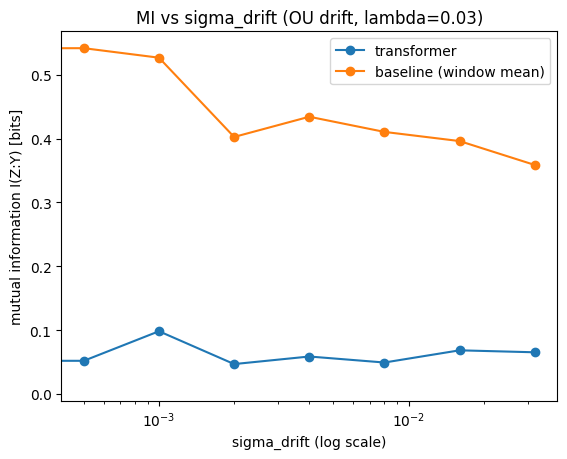

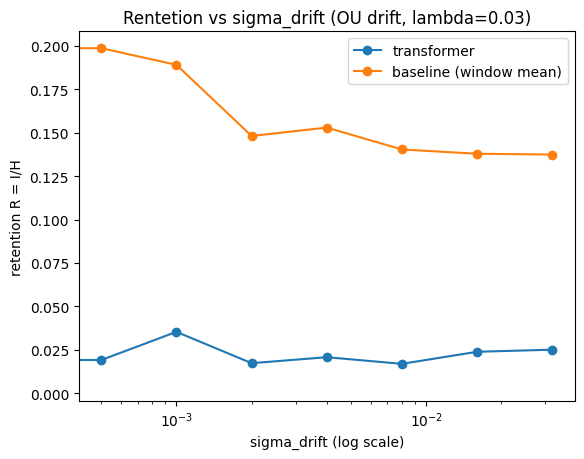

In [11]:
import matplotlib.pyplot as plt

s = [r["sigma_drift"] for r in results_ou]
mi_tf = [r["MI_transformer"] for r in results_ou]
mi_b = [r["MI_baseline_window"] for r in results_ou]
r_tf = [r["R_transformer"] for r in results_ou]
r_b = [r["R_baseline_window"] for r in results_ou]

plt.figure()
plt.plot(s, mi_tf, marker="o")
plt.plot(s, mi_b, marker="o")
plt.xscale("log")
plt.xlabel("sigma_drift (log scale)")
plt.ylabel("mutual information I(Z:Y) [bits]")
plt.title(f"MI vs sigma_drift (OU drift, lambda={lambda_ou})")
plt.legend(["transformer", "baseline (window mean)"])
plt.show()

plt.figure()
plt.plot(s, r_tf, marker="o")
plt.plot(s, r_b, marker="o")
plt.xscale("log")
plt.xlabel("sigma_drift (log scale)")
plt.ylabel("retention R = I/H")
plt.title(f"Rentetion vs sigma_drift (OU drift, lambda={lambda_ou})")
plt.legend(["transformer", "baseline (window mean)"])
plt.show()

In [12]:
import json
from datetime import datetime

# ---- CONFIG--------
config = {
    # data/generator
    "scenario": "ou_process_sweep",
    "T": T,
    "D": 256,
    "K": K,
    "subset_size": 25,
    "overlap_target": 5,
    "seed_world": seed_world,
    "seed_world": seed_nodes,

    # evaluation protocol
    "window": window,
    "mask_ratio": mask_ratio,
    "mask_seed": 2,
    "train_val_split": 0.8,
    "bins": bins.tolist(),

    # sweep
    "sigmas": [r["sigma_drift"] for r in results_ou],

    # model_file
    "model_weights": "run1_clean_model.pt",

    # model hyperparameters (must match how we trained)
    "model_hparams": {
        "d_model": 128,
        "nhead": 4,
        "num_layers": 3,
        "dim_ff": 256,
        "dropout": 0.1
    }
}

run = {
    "config": config,
    "results": results_ou
}

# ---- save ----
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
fname = f"drift_sweep_run_{stamp}.json"

with open(fname, "w") as f:
    json.dump(run, f, indent=2)

print("saved:", fname)

saved: drift_sweep_run_20260201_202426.json


In [13]:
import csv

csv_name = fname.replace(".json", ".csv")
keys = results_ou[0].keys()

with open(csv_name, "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=keys)
    w.writeheader()
    w.writerows(results_ou)

print("saved:", csv_name)


saved: drift_sweep_run_20260201_202426.csv
